# Example 3: a parameter study with many models in parallel

How does the 3 µm water-ice band show up in the polarisation of the scattered light? A grid of 12
models of a nearly edge-on ring (i = 88°, 2.5–3.8 µm):

* 3 grain compositions: astronomical silicate, and silicate with 20 % and 50 % crystalline water ice
  (Maxwell–Garnett mixtures of Kim et al. 2019),
* 2 stars: a G and an A star; the brighter star blows out larger grains,
* 2 size distributions: q = 3.5 and 3.0.

**Parallel computing happens on two levels.** Inside one model, DMS uses OpenMP threads
(`omp_threads` = `OMP_NUM_THREADS` of each run). `dms.batch` runs `workers` models at the same time,
each as its own process. `workers × omp_threads` should not exceed the number of cores: many small
models run fastest with many workers and one or two threads each, a few large images with fewer
workers and more threads. (A single `Model.run` from Python uses OpenMP alone; set
`OMP_NUM_THREADS` before starting Jupyter.)

`dms.batch` needs the command-line program `bin/dms` (`make`). About half a minute on two cores.

In [1]:
# Setup: this notebook lives in the examples/ folder of the repository
import os, sys
REPO = os.environ.get("DMS_REPO") or os.path.abspath("..")
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__, "from", os.path.relpath(os.path.dirname(dms.__file__), REPO))
from dms import batch
import glob

DMS 2.0.0 from python/dms


## What is common to all models

In [2]:
OUT = "parameter_study"                   # queue/, runs/ (one folder per model) and runs/_cache/
QUEUE, RUNS = os.path.join(OUT, "queue"), os.path.join(OUT, "runs")

base = dms.Model(
    run={"mode": "image", "emission": "polarisation", "output_format": "ascii"},
    star={"distance": 10.0},
    disk={"r_in": 80.0, "r_out": 120.0, "opening_angle": 5.0, "dust_mass": 1e-8,
          "inclination": 88.0},                  # nearly edge-on: all scattering angles are seen
    image={"n_pixels": 61, "n_split_max": 2},    # only disk-integrated quantities are used here
    wavelengths={"lambda_min": 2.5, "lambda_max": 3.8, "n_lambda": 27},
    dust={"n_components": 1, "a_min": 0.1, "a_max": 1000.0, "n_sizes": 120,   # 30 bins per decade
          "blowout": True},                      # grains below the blow-out size are removed
    scattering={"n_angles": 181},
)

## The grid

Every combination of the values in `AXES`. A parameter in `LINKED` changes together with an axis
(one value per value of the axis): the bulk density with the composition, the radius and mass with
the stellar temperature.

In [3]:
COMPOSITIONS = {                          # label: (optical data, bulk density [g/cm^3], by volume)
    "silicate": ("kim2019/astrosilicate/astrosilicate_draine2003.txt", 3.5),
    "ice20": ("kim2019/ice_astrosilicate_MG/Sil80cice20", 0.8 * 3.5 + 0.2 * 1.0),
    "ice50": ("kim2019/ice_astrosilicate_MG/Sil50cice50", 0.5 * 3.5 + 0.5 * 1.0),
}
STARS = {"G": (5800.0, 1.0, 1.0), "A": (8590.0, 1.84, 1.92)}    # T_eff [K], R [R_sun], M [M_sun]

AXES = {
    "dust.optical_data": [c[0] for c in COMPOSITIONS.values()],
    "star.teff": [s[0] for s in STARS.values()],
    "dust.q": [3.5, 3.0],
}
LINKED = {
    "dust.optical_data": {"dust.bulk_density": [c[1] for c in COMPOSITIONS.values()]},
    "star.teff": {"star.radius": [s[1] for s in STARS.values()],
                  "star.mass": [s[2] for s in STARS.values()]},
}

def label(values):
    """Short model name, e.g. ice20_A_q3.5."""
    comp = [k for k, c in COMPOSITIONS.items() if c[0] == values["dust.optical_data"]][0]
    star = [k for k, s in STARS.items() if s[0] == values["star.teff"]][0]
    return f"{comp}_{star}_q{values['dust.q']}"

jobs = batch.grid(base, AXES, linked=LINKED, name=label)
print(len(jobs), "models:", ", ".join(j[0] for j in jobs))

12 models: silicate_G_q3.5, silicate_G_q3.0, silicate_A_q3.5, silicate_A_q3.0, ice20_G_q3.5, ice20_G_q3.0, ice20_A_q3.5, ice20_A_q3.0, ice50_G_q3.5, ice50_G_q3.0, ice50_A_q3.5, ice50_A_q3.0


## Run

Each model becomes an input file in the queue folder; `batch.run` returns when the queue is empty.
Models that are already finished are skipped, so a stopped study continues where it stopped. Models
that differ only in the star share one Mie calculation (optics cache). The same queue can also be
run from a terminal or on another computer: `python -m dms.batch run queue runs -j 8`.

In [4]:
todo = [j for j in jobs if not os.path.isfile(os.path.join(RUNS, j[0], "result.json"))]
batch.write_queue(todo, QUEUE, overwrite=True)

omp_threads = 1                                   # OpenMP threads per model
workers = max(1, (os.cpu_count() or 1) // omp_threads)
print(f"{len(jobs)} models, {len(todo)} to compute: {workers} at a time, {omp_threads} thread(s) each")
status = batch.run(QUEUE, RUNS, workers=workers, omp_threads=omp_threads)

12 models, 12 to compute: 2 at a time, 1 thread(s) each
20:03:05 start ice20_A_q3.0


20:03:05 start ice50_A_q3.0


20:03:15 done   ice50_A_q3.0 (10.0 s)


20:03:15 start ice20_A_q3.5


20:03:15 done   ice20_A_q3.0 (10.1 s)


20:03:15 start ice20_G_q3.0


... (15 outputs left out)

20:03:31 start silicate_G_q3.5


20:03:31 done   silicate_G_q3.0 (1.7 s)


20:03:32 done   silicate_G_q3.5 (1.3 s)


20:03:32 finished: 12 done, 0 failed


## Results

`batch.collect` returns one dict per model (`result.json`: wavelengths, SED, degree of polarisation
against scattering angle, f_d, ...); `batch.dop_at(row, 90)` is the degree of polarisation at a
scattering angle of 90° at every wavelength. The smallest grain left after blow-out is read from the
grain-size output file of each model.

In [5]:
rows = {r["name"]: r for r in batch.collect(RUNS)}
lam = np.array(rows[jobs[0][0]]["wavelength"])
i_band = np.abs(lam - 3.1).argmin()               # centre of the crystalline-ice band
i_cont = 0                                        # continuum at 2.5 micron

def smallest_grain(name):
    f = glob.glob(os.path.join(RUNS, name, "grain_size_distribution*.dat"))[0]
    g = np.loadtxt(f, comments="#", ndmin=2)        # columns: component, a, a_low, a_high, N, ...
    return g[g[:, 4] > 0, 1].min()

print(f"{'model':18s} {'a_min [um]':>10s} {'f_d':>9s}   DoP(90 deg) at {lam[i_cont]:.2f} / {lam[i_band]:.2f} micron")
for name, _ in jobs:
    r = rows[name]
    dop90 = np.array(batch.dop_at(r, 90), dtype=float)
    print(f"{name:18s} {smallest_grain(name):10.2f} {r['f_d']:9.2e}   "
          f"{100 * dop90[i_cont]:5.1f} % / {100 * dop90[i_band]:5.1f} %")

model              a_min [um]       f_d   DoP(90 deg) at 2.50 / 3.08 micron
silicate_G_q3.5          0.48  5.98e-05     0.9 % /   8.7 %
silicate_G_q3.0          0.48  1.04e-05     9.4 % /  13.9 %
silicate_A_q3.5          3.29  2.51e-05    32.9 % /  27.5 %
silicate_A_q3.0          3.29  7.98e-06    53.3 % /  49.4 %
ice20_G_q3.5             0.52  6.40e-05     1.5 % /  45.9 %
ice20_G_q3.0             0.52  1.19e-05     8.6 % /  53.4 %
ice20_A_q3.5             3.55  2.83e-05    19.0 % /  75.6 %
ice20_A_q3.0             3.55  9.27e-06    45.1 % /  77.5 %
ice50_G_q3.5             0.56  7.12e-05     8.9 % /  67.6 %
ice50_G_q3.0             0.56  1.51e-05    13.3 % /  70.5 %
ice50_A_q3.5             4.47  3.37e-05    18.0 % /  77.5 %
ice50_A_q3.0             4.47  1.20e-05    42.8 % /  76.9 %


## Figure

Degree of polarisation at a scattering angle of 90° against wavelength for q = 3.5 and 3.0, and
against the scattering angle at 3.1 µm (solid: G star, dashed: A star). With the A star the size
distribution starts at the blow-out size (a few µm), and its sharp lower edge leaves Mie
oscillations in the curves.

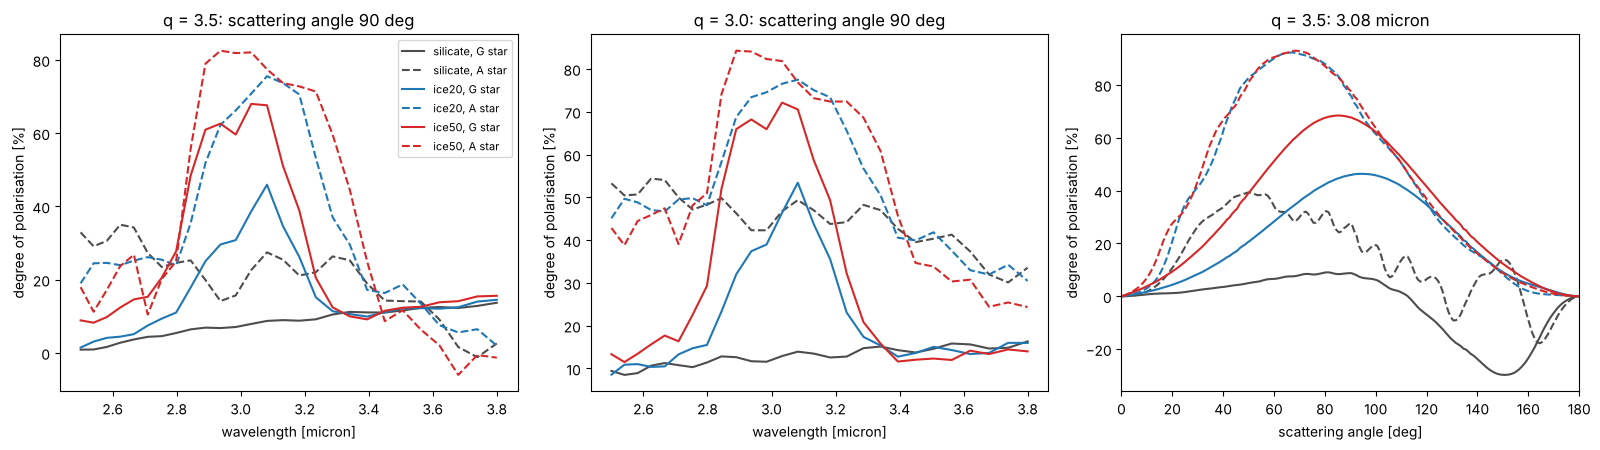

In [6]:
colours = {"silicate": "0.3", "ice20": "C0", "ice50": "C3"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for k, q in enumerate([3.5, 3.0]):
    for comp in COMPOSITIONS:
        for star, ls in (("G", "-"), ("A", "--")):
            r = rows[f"{comp}_{star}_q{q}"]
            ax[k].plot(lam, 100 * np.array(batch.dop_at(r, 90), dtype=float), ls=ls,
                       color=colours[comp], label=f"{comp}, {star} star")
    ax[k].set_title(f"q = {q}: scattering angle 90 deg")
    ax[k].set_xlabel("wavelength [micron]")
    ax[k].set_ylabel("degree of polarisation [%]")
ax[0].legend(fontsize=8)

theta = np.array(rows[jobs[0][0]]["theta"])
for comp in COMPOSITIONS:
    for star, ls in (("G", "-"), ("A", "--")):
        d = np.array(rows[f"{comp}_{star}_q3.5"]["dop_theta"][i_band], dtype=float)
        ax[2].plot(theta, 100 * d, ls=ls, color=colours[comp], label=f"{comp}, {star} star")
ax[2].set_title(f"q = 3.5: {lam[i_band]:.2f} micron")
ax[2].set_xlabel("scattering angle [deg]")
ax[2].set_ylabel("degree of polarisation [%]")
ax[2].set_xlim(0, 180)
fig.tight_layout()
plt.show()